# Response to reviewers: sensitivity analysis and error propagation

This notebook provides the evidence for the four responses in [`response_to_reviewers.md`](response_to_reviewers.md):

| Reviewer comment | Analysis | Linked evidence |
|---|---|---|
| Comment 1 | Voxel-size sensitivity (5-25 cm) | Supplementary Figure S2 |
| Comment 2 | Error propagation through the pipeline | Supplementary Figure S1 and Table S1 |
| Comment 3 | Sensitivity to the 0.30 m matching radius | Supplementary Figure S4(a, e) |
| Comment 4 | Impact of selected parameter values | Supplementary Figure S4 and Table S2 |

The complete workflow was evaluated on 30 tiles (15 per site). Figures and tables are generated from the CSV outputs of [`sensitivity.py`](sensitivity.py).

In [ ]:
from pathlib import Path

import sys



import pandas as pd

from IPython.display import Image, Markdown, display



HERE = Path.cwd() if (Path.cwd() / "figures.py").exists() else Path.cwd() / "reviewer_response"

sys.path.insert(0, str(HERE))



import figures as fg

import sensitivity as sv



ASSETS = sv.OUTPUT_DIR

per_tile = pd.read_csv(ASSETS / "parameter_sensitivity_per_tile.csv")

label_quality = pd.read_csv(ASSETS / "label_quality_summary.csv")



REDRAW = False





def figure(name, draw):

    """Show a saved figure, redrawing it first when requested."""

    path = ASSETS / name

    if REDRAW or not path.with_suffix(".png").exists():

        draw(path)

    display(Image(filename=str(path.with_suffix(".png"))))





display(per_tile[per_tile["Parameter"] != "input"]

        .groupby(["Parameter", "Site condition"])["Tile"].nunique().unstack()

        .rename_axis(columns="Tiles per site"))

Tiles per site,Low,Medium
Parameter,,
height_match_radius,15,15
height_prior_out_of_range_weight,15,15
min_conf,15,15
min_flip_ratio,15,15
voxel_size,15,15


## Comment 2: error propagation

**Linked evidence: Supplementary Figure S1 and Table S1**

> *Could the authors explicitly quantify or qualitatively characterise the error introduced at each step of the pipeline?*

Intermediate products use different units, so each was rasterised onto the 5 cm grid and scored as plan-view mean intersection-over-union (mIoU) against the annotator's 1 cm raster. Differences between successive levels show where agreement is lost; they are not independent error terms.

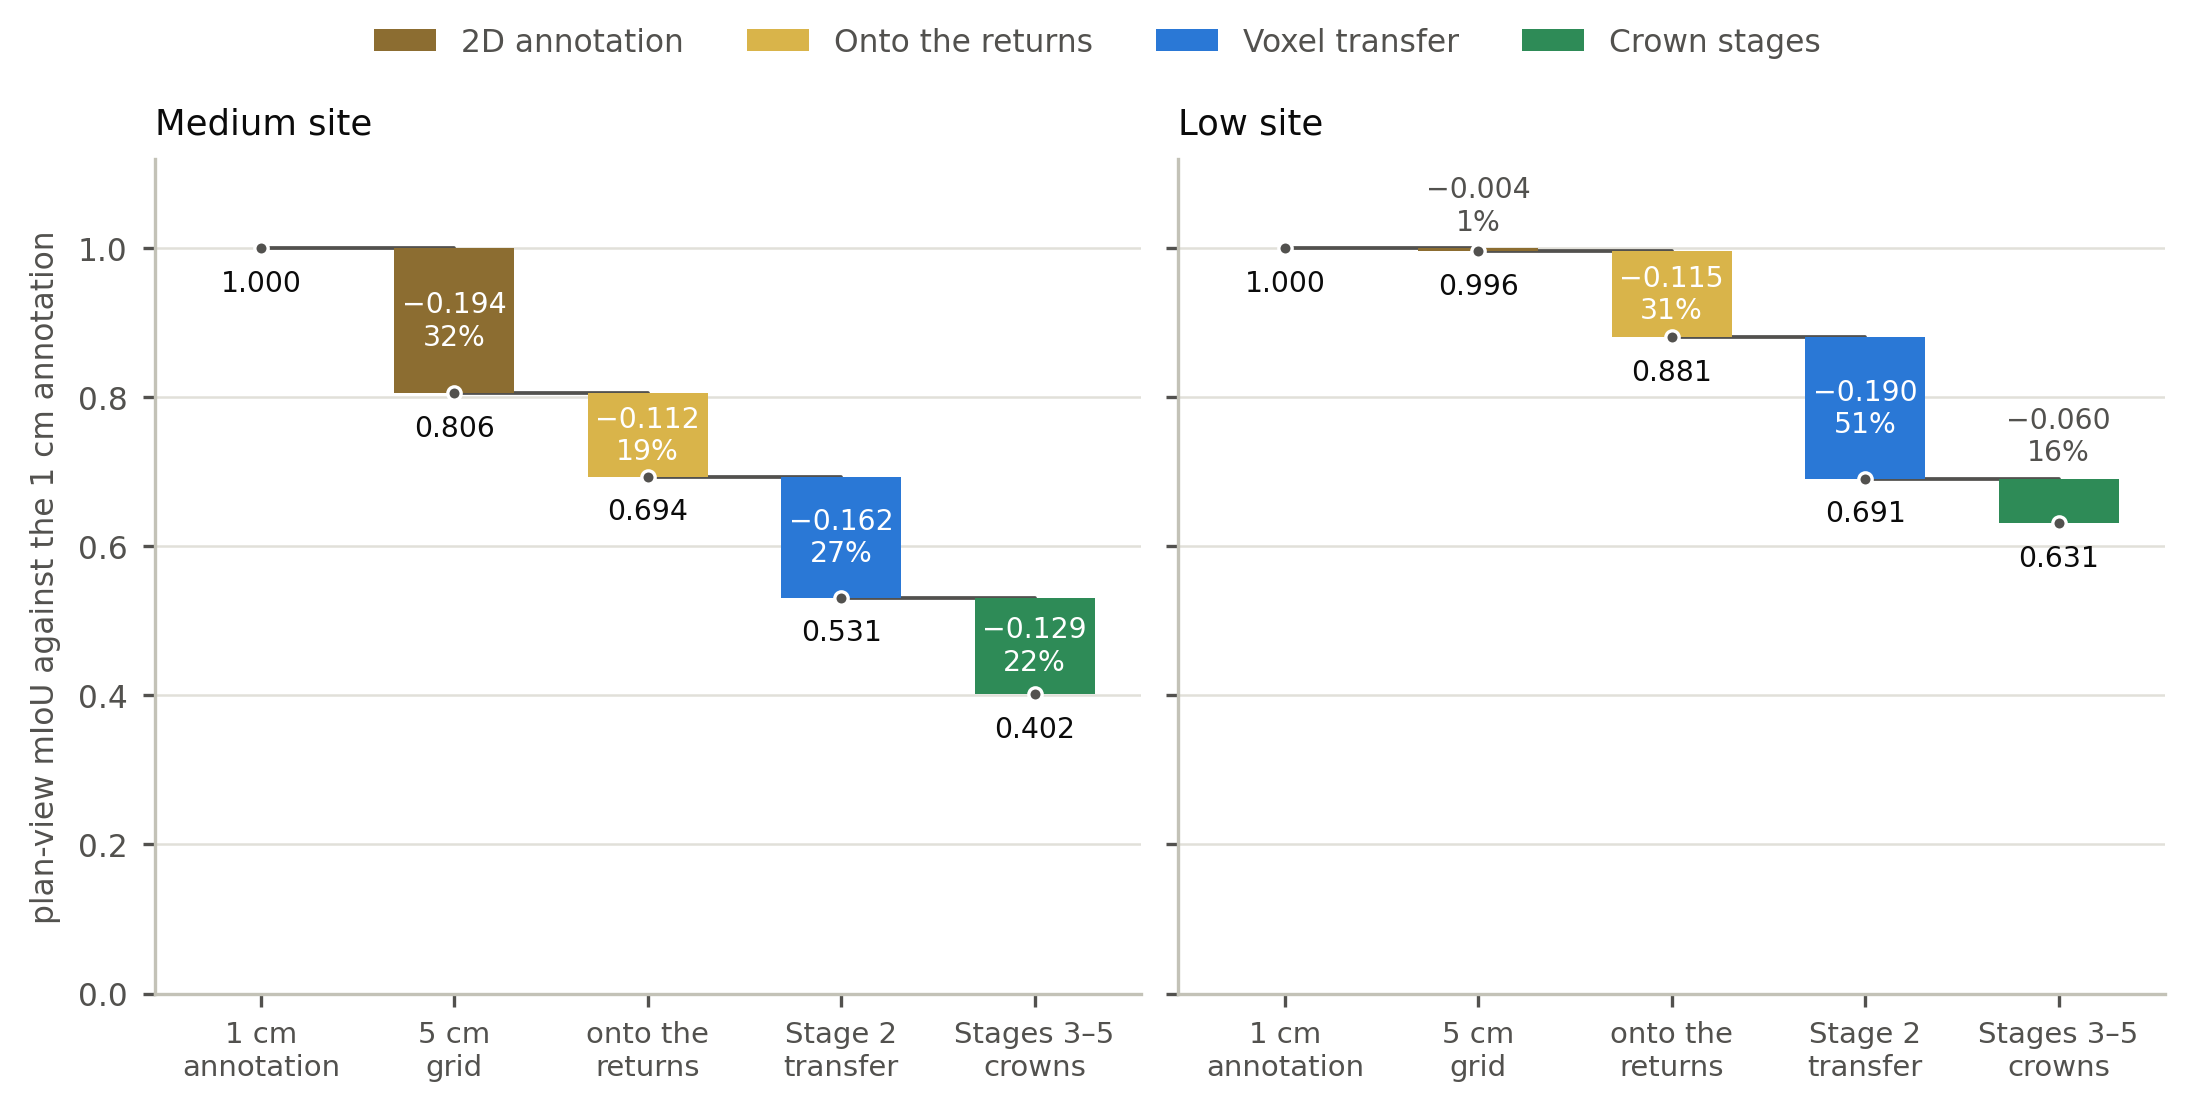

| Step | Part of the pipeline | Medium: mIoU | Medium: lost | Low: mIoU | Low: lost |
|---|---|---:|---:|---:|---:|
| The annotator's 1 cm raster | 2D annotation | 1.000 | – | 1.000 | – |
| 1 cm → 5 cm label grid | 2D annotation | 0.806 | -0.194 | 0.996 | -0.004 |
| 5 cm labels → labelled lidar returns | Onto the returns | 0.694 | -0.112 | 0.881 | -0.115 |
| Stage 2: voxel transfer (10 cm) | Voxel transfer | 0.531 | -0.162 | 0.691 | -0.190 |
| Stages 3–5: crown detection, refinement, vote | Crown stages | 0.402 | -0.129 | 0.631 | -0.060 |

Share of the total loss, step by step in the order above — **Medium** 32%, 19%, 27%, 22% (total 0.598); **Low** 1%, 31%, 51%, 16% (total 0.369).

In [2]:
figure("supplementary_error_budget",
       lambda p: fg.plot_error_budget(per_tile, label_quality, p))
display(Markdown(fg.error_budget_table(per_tile, label_quality)))

**Answer.** The relative contributions differ by site. At the medium site, 1 cm to 5 cm

downsampling is the largest loss (0.194 of 0.598 total); at the low site, voxel transfer is the

largest loss (0.190 of 0.369). The table below also characterises each step in its native units.



These values measure fidelity to the 2D annotation, not absolute 3D accuracy, because no

independent 3D reference labels are available.

In [9]:
display(Markdown(fg.error_sources_table(per_tile, label_quality)))

| Step | What it introduces | How it is measured | Medium | Low |
|---|---|---|---:|---:|
| Delineation | Where the annotator put each boundary | IoU of the class eroded against the class dilated by ±5 cm (a floor, not an estimate) | 0.321 / 0.254 | 0.508 / 0.547 |
| Delineation | Pixels claimed by two classes at once | Cross-class overlap, share of labelled area | 0.021% | 0.161% |
| Polygon → 1 cm raster | Rasterisation and draw-order resolution of overlaps | Class IoU, polygons rasterised exactly against the delivered 1 cm raster | 0.924 / 0.934 | 0.679 / 0.957 |
| 1 cm → 5 cm grid | Downsampling onto a grid that does not divide the tile | Class IoU against the majority of each cell's 1 cm sub-pixels | 0.806 / 0.804 | 0.996 / 0.997 |
| 1 cm → 5 cm grid | How far a feature's centre moves | Centroid RMSE per polygon | 0.012 m | 0.007 m |
| 5 cm labels → returns | Labelled cells holding no lidar return cannot be labelled | Plan-view mIoU of the labelled returns against the 5 cm raster they came from | 0.925 / 0.953 | 0.884 / 0.899 |
| 5 cm labels → returns | Returns on labelled cells missing from the structure cloud | Share of the lidar points on labelled cells, all tiles | 362 (0.005%) | 0 (0.000%) |
| Stage 1: height lookup | The nearest-neighbour search is in XY only | Largest shift in any class height range it causes, any tile | 0.017 m | 0.003 m |
| Stage 1: height lookup | Points beyond the 0.30 m matching radius | Share of structure points, any tile | 0.000% | 0.000% |
| Stage 2: voxel transfer | Labels extended past their 2D footprint | Share of the labels the transfer assigns | 12.5 / 11.8% | 16.0 / 15.9% |
| Stage 2: voxel transfer | Labels lost inside their 2D footprint | 100 − footprint recall, worst tile at any voxel size | 1.18% | 2.27% |
| Stage 2: voxel transfer | Voxels holding more than one class, settled by majority | Share of occupied voxels | 0.24 / 0.14% | 0.92 / 0.84% |
| Stage 4: crown refinement | Labels the polar refinement changes inside crowns | Share of all lidar points | 0.531 / 0.544% | 0.051 / 0.000% |
| Stage 5: crown vote | Crowns turned wholly mallee, overwriting Stage 4 | Crowns voted, of which mallee-majority | 816, 815 mallee | 8, 0 mallee |
| Stage 5: crown vote | Unlabelled returns promoted to mallee on height alone | Share of all lidar points | 1.824 / 1.852% | 0.020 / 0.000% |
| Stage 5: crown vote | Woody debris removed: it is not a growth form | Plan-view IoU, Stage 2 → final | 0.535 → 0.000 | 0.662 → 0.000 |

## Comment 1: voxel-size sensitivity (5-25 cm)

**Linked evidence: Supplementary Figure S2**

> *The choice of 10 cm voxel size appears empirical. Could the authors compare 5, 10, 15, 20 and 25 cm and include the results as a supplementary figure?*

The complete workflow was run at all five sizes on all 30 tiles. Supplementary Figure S2 shows the median and interquartile range across the 15 tiles at each site.

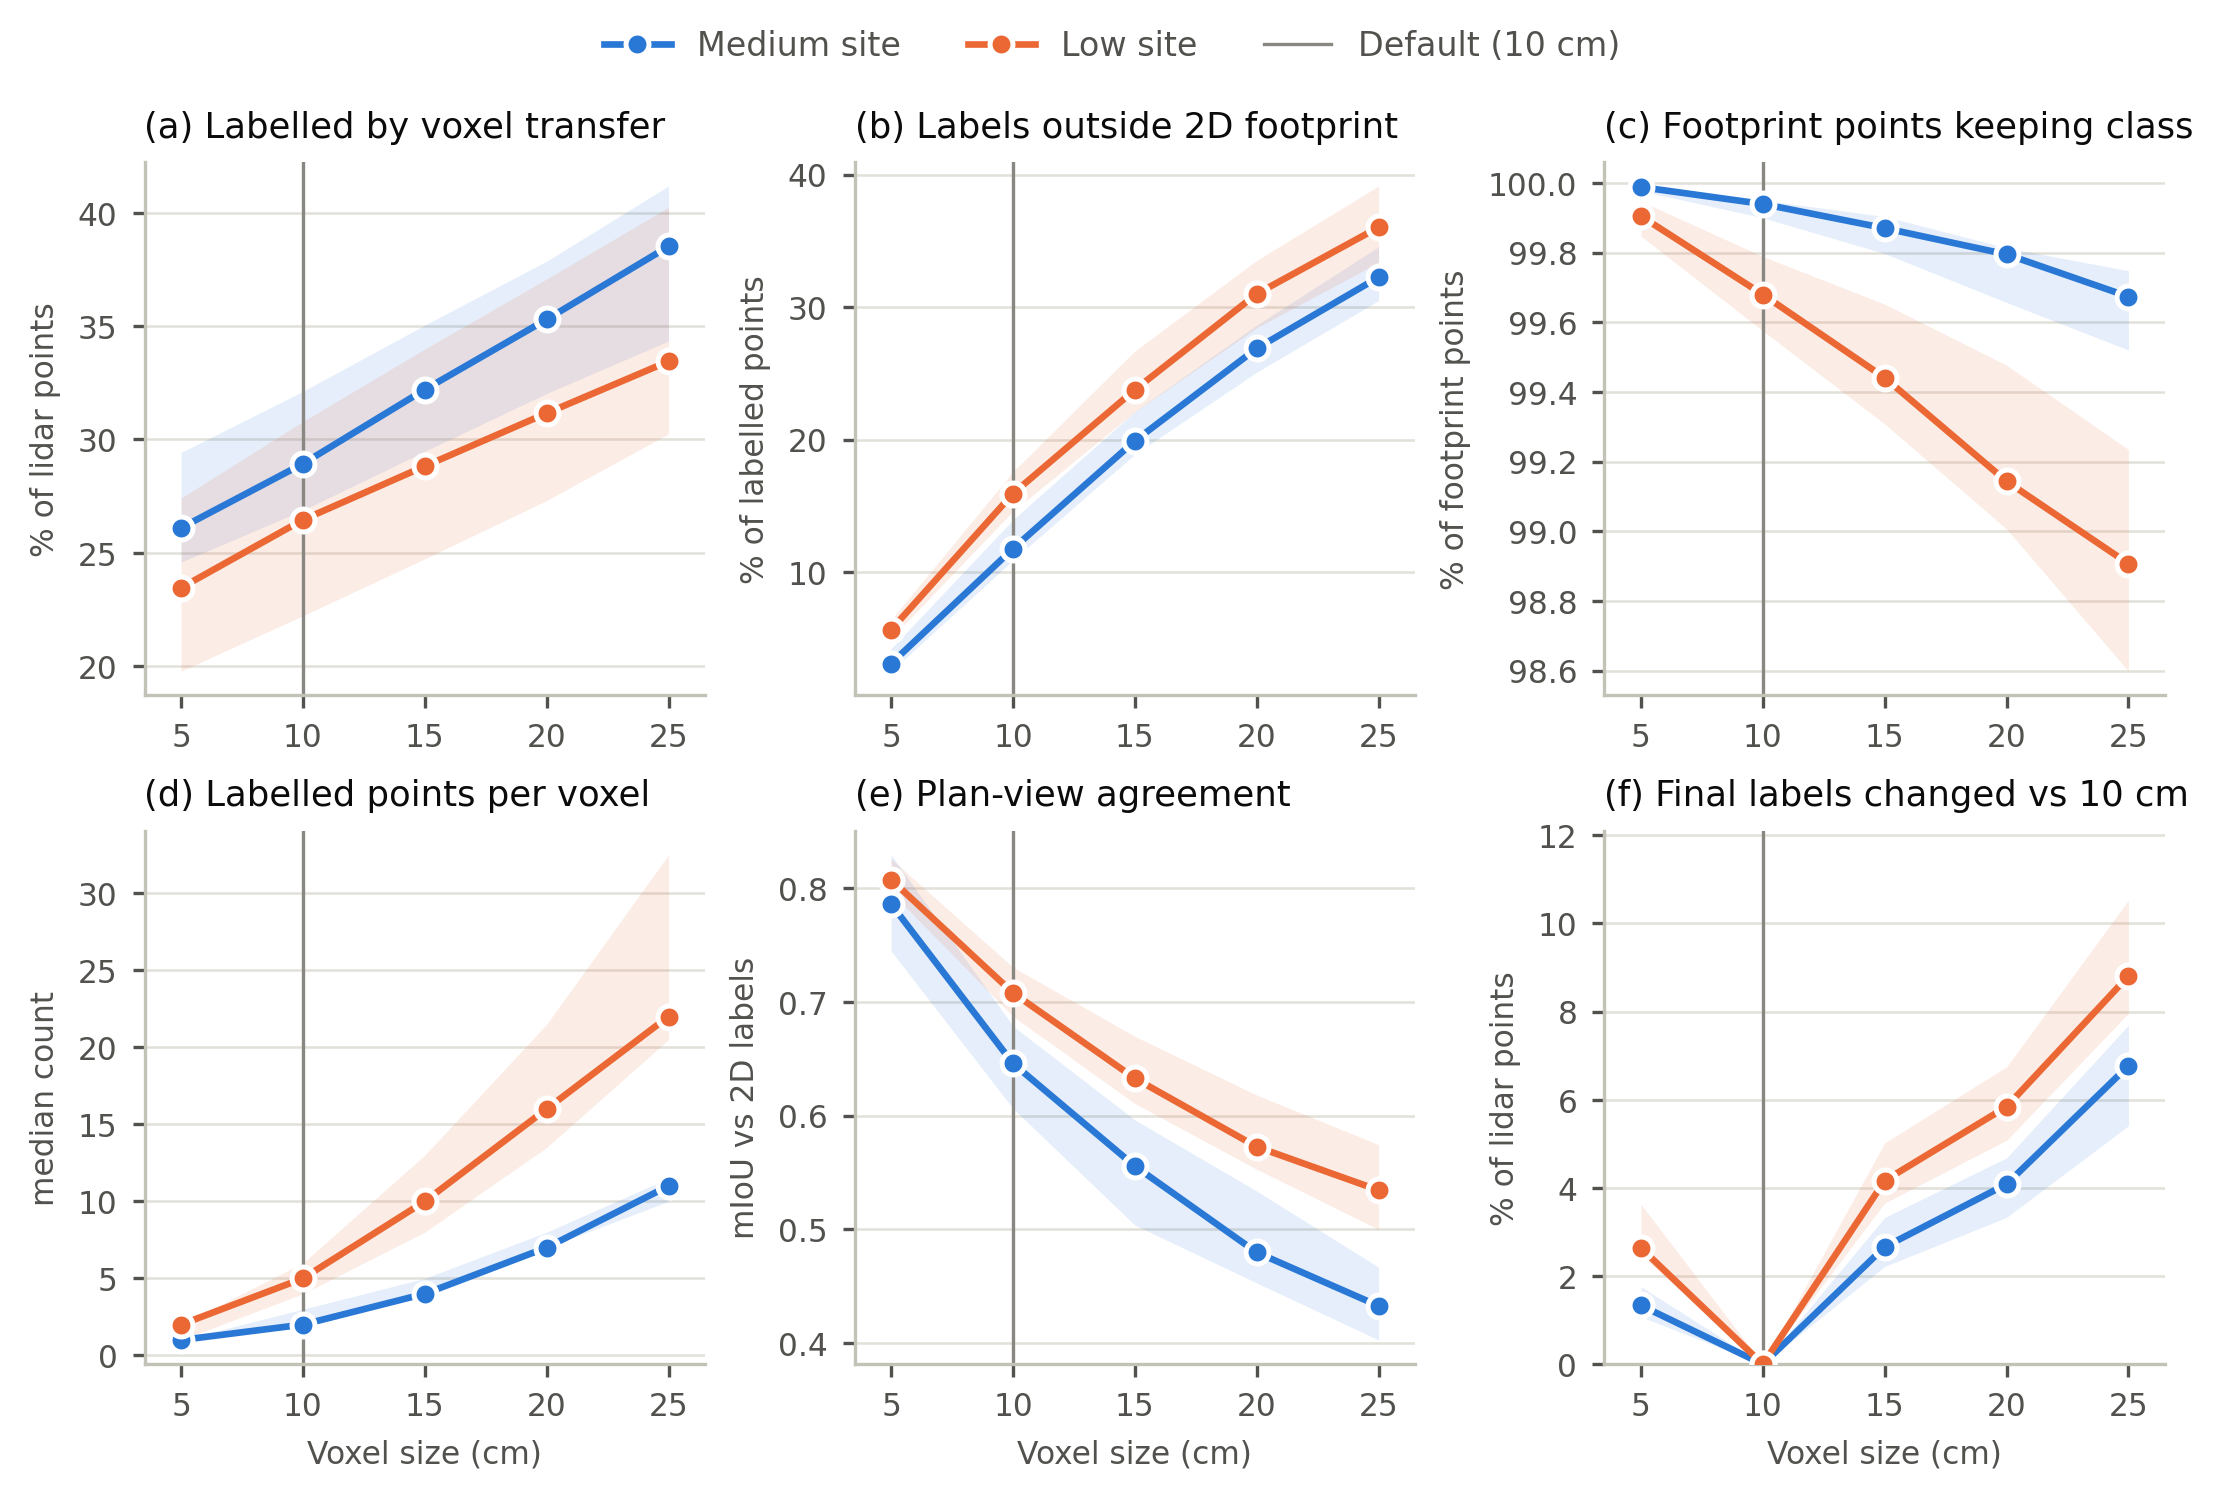

| Site | Voxel size (cm) | Labelled by transfer (%) | Outside footprint (%) | Footprint recall (%) | mIoU vs 5 cm input | Points per voxel | Single-point voxels (%) | Mixed-class voxels (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 27.2 / 26.1 | 3.5 / 3.1 | 99.97 / 99.99 | 0.787 / 0.786 | 1.0 / 1.0 | 67.2 / 69.3 | 0.04 / 0.02 |
| Medium | **10** | 30.0 / 28.9 | 12.5 / 11.8 | 99.89 / 99.94 | 0.648 / 0.646 | 2.3 / 2.0 | 33.9 / 35.2 | 0.24 / 0.14 |
| Medium | 15 | 33.0 / 32.2 | 20.6 / 19.9 | 99.80 / 99.87 | 0.556 / 0.556 | 4.4 / 4.0 | 20.4 / 20.7 | 0.59 / 0.39 |
| Medium | 20 | 35.9 / 35.3 | 27.0 / 26.9 | 99.69 / 99.80 | 0.495 / 0.480 | 7.6 / 7.0 | 14.7 / 15.1 | 1.04 / 0.78 |
| Medium | 25 | 38.8 / 38.5 | 32.5 / 32.3 | 99.57 / 99.67 | 0.446 / 0.433 | 11.6 / 11.0 | 11.6 / 11.7 | 1.64 / 1.29 |
| Low | 5 | 24.4 / 23.5 | 5.7 / 5.6 | 99.88 / 99.90 | 0.787 / 0.808 | 1.5 / 2.0 | 48.3 / 46.7 | 0.20 / 0.17 |
| Low | **10** | 27.4 / 26.4 | 16.0 / 15.9 | 99.68 / 99.68 | 0.692 / 0.708 | 5.0 / 5.0 | 17.6 / 16.8 | 0.92 / 0.84 |
| Low | 15 | 30.4 / 28.8 | 24.2 / 23.8 | 99.45 / 99.44 | 0.624 / 0.633 | 10.5 / 10.0 | 11.0 / 11.3 | 1.85 / 1.82 |
| Low | 20 | 33.3 / 31.2 | 30.8 / 31.0 | 99.21 / 99.14 | 0.572 / 0.572 | 17.2 / 16.0 | 8.4 / 8.3 | 2.80 / 2.74 |
| Low | 25 | 36.1 / 33.4 | 36.2 / 36.0 | 98.92 / 98.91 | 0.526 / 0.534 | 25.6 / 22.0 | 7.1 / 6.9 | 3.81 / 3.79 |

In [5]:
figure("supplementary_voxel_size_sensitivity", lambda p: fg.plot_voxel_figure(per_tile, p))

display(Markdown(fg.table(per_tile, "voxel_size", fg.TRANSFER_COLUMNS)))

**Answer.** Agreement with the 2D labels decreases monotonically as voxel size increases because

larger voxels propagate labels farther beyond their 2D footprints. Therefore, this comparison

documents a trade-off and does not identify an accuracy optimum.



The 10 cm value was selected from return spacing. Labelled returns are spaced about 4.5 cm at the

medium site and 5.6 cm at the low site. A 5 cm voxel usually contains one labelled return and has

little to merge; 10 cm is approximately twice the mean spacing, increases co-occupancy, and keeps

mixed-class voxels below 1%. At larger sizes, class mixing rises as voxels approach the scale of

the mapped features. Thus, 10 cm is a survey-density-based compromise rather than an empirically

tuned optimum.

In [6]:
display(Markdown(fg.spacing_table(per_tile)))

| Site | Labelled returns per m² | Mean spacing (cm) | 5 cm | 10 cm | 15 cm | 20 cm | 25 cm |
|---|---:|---:|---:|---:|---:|---:|---:|
| Medium | 493 | 4.51 | 1.11× | 2.22× | 3.33× | 4.44× | 5.55× |
| Low | 321 | 5.58 | 0.90× | 1.79× | 2.69× | 3.58× | 4.48× |

## Comment 3: sensitivity to the 0.30 m matching radius

**Linked evidence: Supplementary Figure S4(a, e)**

> *Please explain why the 0.30 m matching radius was selected.*

The radius is the maximum XY distance used to match each labelled point to the height-normalised cloud in Stage 1. It is a guard against unmatched points, not a tuned spatial scale.

In [10]:
display(Markdown(fg.input_table(per_tile)))

| Check | Medium | Low |
|---|---:|---:|
| Tiles | 15 | 15 |
| Structure points with an exact Z_norm twin, lowest tile (%) | 100.000 | 100.000 |
| Largest XY match distance, any tile (m) | 0.000 | 0.000 |
| Structure points beyond the 0.30 m radius, any tile (%) | 0.000 | 0.000 |
| Largest class-range shift from XY-only matching, any tile (m) | 0.017 | 0.003 |

**Answer.** The labelled points are lidar returns, so all points had exact counterparts in the

height-normalised cloud and matched at 0.000 m on all 30 tiles. Repeating the workflow with radii

of 0.01, 0.05, 0.10, 0.30 and 1.00 m produced identical final labels. Therefore, 0.30 m is a

conservative upper bound that never affects this dataset.

## Comment 4: impact of selected parameter values

**Linked evidence: Supplementary Figure S4 and Table S2**

> *Please explain why voxel size (10 cm), weighting (1, 0.1), confidence threshold and flip ratio were selected at their current values.*

Each parameter was varied independently while all others remained at their defaults. The table summarises the tested values and the largest final-label change on any tile.

In [11]:
display(Markdown(fg.answer_table(per_tile)))

| Parameter | Default | What it decides | Values tested | Medium: largest change (%) | Low: largest change (%) |
|---|---:|---|---|---:|---:|
| Voxel size | 10 cm | how far a 2D label extends to neighbouring returns | 5, 10, 15, 20, 25 | 9.24 | 16.28 |
| Matching radius | 0.3 m | how far a point may look for its height above ground | 0.01, 0.05, 0.1, 0.3, 1 | 0.00 | 0.00 |
| Out-of-range weight | 0.1 | how strongly a class outside its height range is penalised | 1, 0.5, 0.1, 0.01, 0 | 0.00 | 0.13 |
| min_conf | 0.3 | whether an unlabelled point inside a crown is filled | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.00 | 0.00 |
| min_flip_ratio | 1.5 | whether an existing label is overturned | 1, 1.25, 1.5, 2, 3 | 0.00 | 0.02 |

Supplementary Figure S4 shows the sensitivity curves. Voxel size is the only parameter that

materially changes the delivered labels; the other parameters mainly affect intermediate Stage-4

assignments.

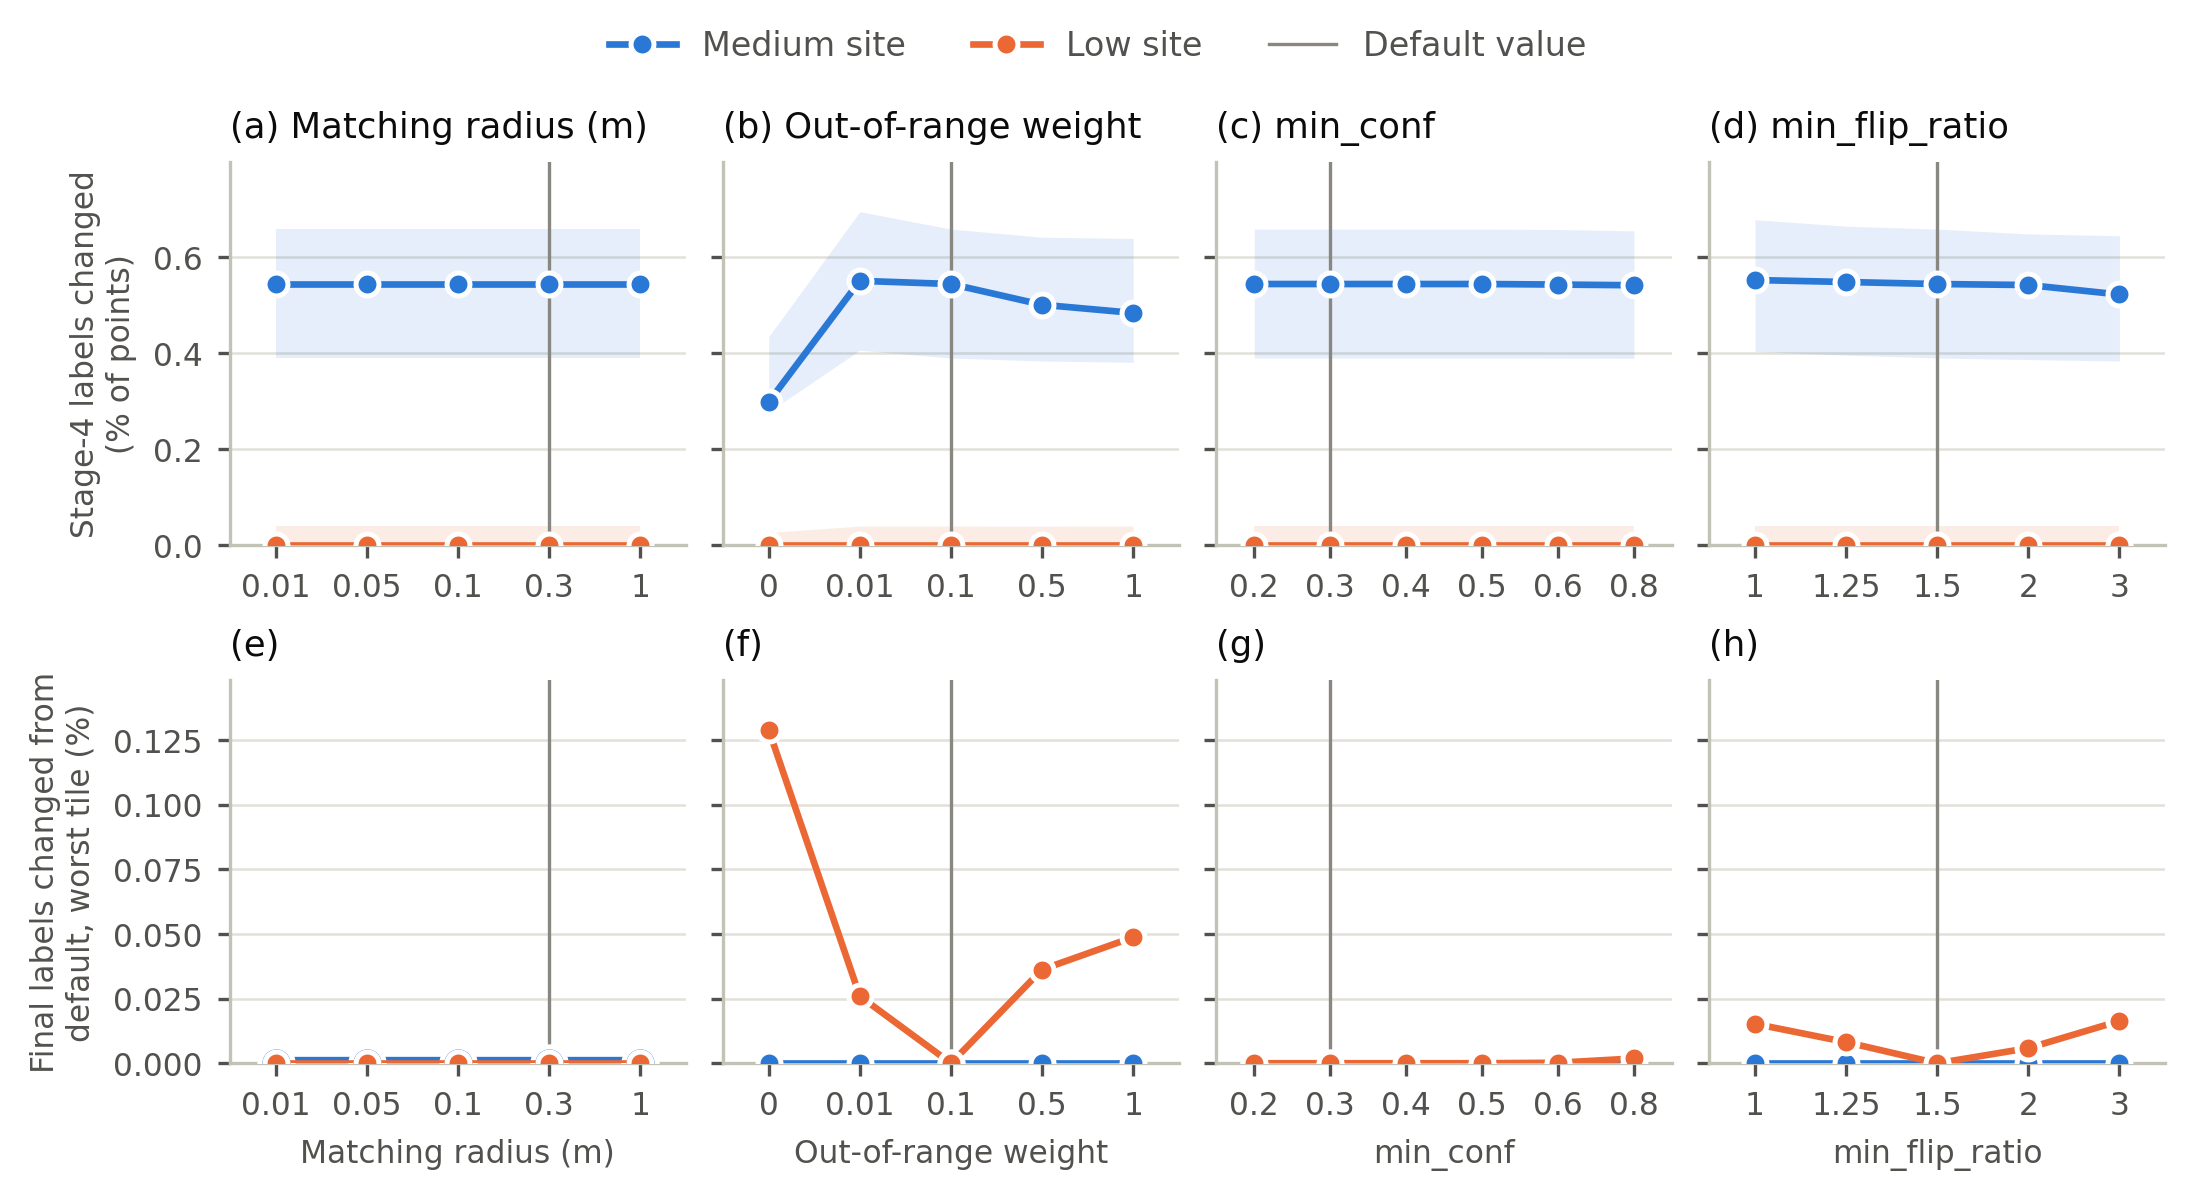

| Parameter | Values tested | Medium: worst tile (%) | Low: worst tile (%) |
|---|---|---:|---:|
| Matching radius (m) | 0.01, 0.05, 0.1, 0.3, 1 | 0.0000 | 0.0000 |
| Out-of-range weight | 1, 0.5, 0.1, 0.01, 0 | 0.0000 | 0.1288 |
| min_conf | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.0000 | 0.0018 |
| min_flip_ratio | 1, 1.25, 1.5, 2, 3 | 0.0000 | 0.0163 |

- Medium site: largest final-label change across 15 tiles and every value of the four parameters **0.0000%** of points; largest Stage-4 change 0.877%; tiles without a detected crown 0 of 15.
- Low site: largest final-label change across 15 tiles and every value of the four parameters **0.1288%** of points; largest Stage-4 change 0.408%; tiles without a detected crown 11 of 15.

In [12]:
figure("supplementary_parameter_sensitivity", lambda p: fg.plot_parameter_figure(per_tile, p))
display(Markdown(fg.worst_table(per_tile) + "\n\n" + fg.invariance_sentences(per_tile)))

**Answer.**



- **Voxel size = 10 cm:** approximately twice the mean spacing of labelled returns, so voxels

  usually contain enough points to merge while mixed-class voxels remain below 1%.

- **Height-prior weights = 1 and 0.1:** in-range evidence is retained and out-of-range evidence is

  down-weighted tenfold. A weight of 1 would disable the prior; 0 would make it a hard veto.

- **`min_conf` = 0.3:** accepts a clear winner among up to three classes but rejects near-ties among

  four or five. It did not bind in these data; mean confidence was 0.999.

- **`min_flip_ratio` = 1.5:** requires a 60:40 majority in a two-class case before replacing an

  inherited label, preventing changes on near-ties.



Across all tested values, the largest final-label change caused by the last three parameters was

0.13% on any tile. Their small effect indicates robustness around the selected defaults rather

than evidence that the defaults were numerically optimized.

## Regenerating the evidence

```bash
cd phase_4_3D_lidar_prep/step_3_structure_class/reviewer_response

# Re-run the measurements for all 30 tiles and five parameter sweeps
python sensitivity.py all --workers 16

# Rebuild Supplementary Figures S1, S2 and S4 and Tables S1-S2
python figures.py
```

Use `--sites`, `--tiles` or `--parameters` with `sensitivity.py` to restrict a run. Set `REDRAW = True` in the setup cell to redraw notebook figures from the CSVs instead of displaying saved PNGs.